<a href="https://colab.research.google.com/github/Daudi-Zacharia/msc-thesis/blob/main/classification/clean_notebooks/d1_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D1 (704-image) Classification Experiments

Clean rebuild of the **D1 experiments reported in Table III**: five architectures,
each trained twice —

| Scheme | Input |
|---|---|
| **Original** | the full chest X-ray |
| **Segmented** | the X-ray multiplied by its predicted lung mask (hard attention), using `seg_unet_2.pth` |

Rebuilt from the per-model notebooks in `classification/raw_notebooks/`. Scratch
runs, soft-attention (SA) variants and UNET-4 variants are deliberately excluded;
they remain in the raw notebooks.

**Checkpoints live in Google Drive, not in this repository:**

```
/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification
/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation      (VGG16 segmented, seg_unet_2.pth)
```

| Model | Original (704) | Segmented (704, HA + aug, UNET2) |
|---|---|---|
| Custom CNN | `custom_run1_aug.pt` | `custom_class_seg_aug_ha.pt` |
| DenseNet169 | `densenet169_704_run2.pt` | `densenet169_704_class_seg_transforms.pt` |
| VGG16 | `vgg16_class_704.pt` | `vgg16_class_seg_transforms.pt` |
| ResNet50 | `resnet50_704_run2.pt` | `resnet50_704_class_seg_transforms.pt` |
| EfficientNetB3 | `efficient_net_704_run2.pt` | `enet_class_seg_704_transforms.pt` |

Requires a GPU runtime with Drive mounted. Training cells are kept for
reproducibility but are not meant to be re-run every pass — each Evaluation cell
loads the saved checkpoint instead.

# 1. Setup

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!pip install kagglehub -q
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 70.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
import os
import random
import shutil
import time

import numpy as np
import pandas as pd
import PIL
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.datasets import ImageFolder

from sklearn.metrics import (confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.manifold import TSNE

# reproducibility
SEED = 7
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# --- Drive locations (checkpoints are NOT in this repo) --------------------
path_classification = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/classification'
path_segmentation = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation'
SEG_CHECKPOINT = os.path.join(path_segmentation, 'seg_unet_2.pth')

# --- local data directories built by this notebook -------------------------
DIR_ORIGINAL = './data_704'        # 70/20/10 split of the raw X-rays
DIR_FLAT = './Images_704'          # all 704 images, unsplit (input to the U-Net)
DIR_ROI = './ROI_Images_704'       # masked images produced by the U-Net
DIR_SEGMENTED = './data_704_seg'   # 70/20/10 split of the masked images

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

Device: cuda


# 2. Helper Functions

Defined once and reused by every model and scheme below. Nothing in the
per-model sections re-implements training, evaluation or plotting.

In [6]:
def train_model(model, train_dl, val_dl, optimizer, loss_fn, save_path,
                epochs=30, patience=10, save_mode='full', device='cpu'):
    """Trains with early stopping, checkpointing the best validation loss.

    save_mode must match how the corresponding checkpoint was originally stored,
    so that the Evaluation cell can load back what Training wrote:
      'full'       -> torch.save(model, ...)              (the default here)
      'state_dict' -> torch.save(model.state_dict(), ...)
    """
    if save_mode not in ('full', 'state_dict'):
        raise ValueError("save_mode must be 'full' or 'state_dict'")

    model.to(device)

    history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},
               'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}}

    best_val_loss = np.inf
    count = 0

    for epoch in range(1, epochs + 1):

        # --- train ---
        model.train()
        t0 = time.time()
        train_loss = 0
        correct = 0

        for batch, target in train_dl:
            inputs, target = batch.to(device), target.to(device)
            output = model(inputs)
            loss = loss_fn(output, target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            correct += (output.argmax(dim=1) == target).sum().item()

        history['Training']['Loss'].append(train_loss / len(train_dl))
        history['Training']['Accuracy'].append(correct / len(train_dl.dataset))
        history['Training']['Time'].append((time.time() - t0) / 60)

        # --- validate ---
        model.eval()
        t0 = time.time()
        val_loss = 0
        correct = 0

        with torch.no_grad():
            for batch, target in val_dl:
                inputs, target = batch.to(device), target.to(device)
                output = model(inputs)

                val_loss += loss_fn(output, target).item()
                correct += (output.argmax(dim=1) == target).sum().item()

        val_loss /= len(val_dl)
        val_acc = correct / len(val_dl.dataset)

        history['Validation']['Loss'].append(val_loss)
        history['Validation']['Accuracy'].append(val_acc)
        history['Validation']['Time'].append((time.time() - t0) / 60)

        # --- checkpoint + early stopping ---
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            count = 0
            torch.save(model.state_dict() if save_mode == 'state_dict' else model,
                       save_path)
            print(f'Best model saved at epoch {epoch}')
        else:
            count += 1

        if count >= patience:
            print(f'Early stopping triggered at epoch {epoch}')
            break

        print(f"Epoch [{epoch}/{epochs}]  "
              f"train loss {history['Training']['Loss'][-1]:.4f}  "
              f"acc {history['Training']['Accuracy'][-1]:.4f}  |  "
              f"val loss {val_loss:.4f}  acc {val_acc:.4f}")

    print(f"\nTotal training time: {sum(history['Training']['Time']):.2f} min")
    return history


def plot_history(history):
    """Training vs validation loss and accuracy."""
    x = range(1, len(history['Training']['Loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, metric in zip(axes, ['Loss', 'Accuracy']):
        ax.plot(x, history['Training'][metric], label=f'Training {metric}')
        ax.plot(x, history['Validation'][metric], label=f'Validation {metric}')
        ax.set_xlabel('Epochs')
        ax.set_ylabel(metric)
        ax.set_title(f'Training and Validation {metric}')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [7]:
def load_checkpoint(path, how='full', builder=None, device='cpu'):
    """Loads a checkpoint saved either as a full object or as a state dict.

    how='full'        -> torch.load(..., weights_only=False)
    how='state_dict'  -> builder() then load_state_dict
    """
    if how == 'state_dict':
        if builder is None:
            raise ValueError("a builder is required to load a state dict")
        model = builder().to(device)
        model.load_state_dict(torch.load(path, map_location=device))
    else:
        model = torch.load(path, map_location=device, weights_only=False)

    model.to(device)
    model.eval()
    return model


def evaluate_model(model, test_dl, title='', device='cpu'):
    """Runs inference and reports the full metric set, a confusion matrix and a ROC curve.

    zero_division=0 keeps an ill-defined metric explicit (e.g. a model that
    collapses onto one class) instead of raising a warning.
    """
    model.to(device)
    model.eval()

    preds, targets, probs = [], [], []

    with torch.no_grad():
        for batch, target in test_dl:
            output = model(batch.to(device))
            preds.append(output.argmax(dim=1).cpu())
            probs.append(F.softmax(output, dim=1)[:, 1].cpu())
            targets.append(target)

    y_pred = torch.cat(preds).numpy()
    y_true = torch.cat(targets).numpy()
    y_prob = torch.cat(probs).numpy()

    metrics = {
        'Acc.': (y_pred == y_true).mean(),
        'Prec.': precision_score(y_true, y_pred, zero_division=0),
        'Sens.': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'Spec.': recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        'AUC': roc_auc_score(y_true, y_prob),
    }

    print(f'--- {title} ---')
    print(f'Test set: n = {len(y_true)} | TB = {int((y_true == 1).sum())} | '
          f'Normal = {int((y_true == 0).sum())}')
    print('  '.join(f'{k} {v:.4f}' for k, v in metrics.items()))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fpr, tpr, _ = roc_curve(y_true, y_prob)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'TB'], yticklabels=['Normal', 'TB'],
                annot_kws={'size': 16, 'weight': 'bold'}, ax=axes[0])
    axes[0].set_xlabel('Predicted Class')
    axes[0].set_ylabel('True Class')
    axes[0].set_title(f'Confusion Matrix - {title}')

    axes[1].plot(fpr, tpr, color='darkorange', lw=2,
                 label=f"ROC curve (AUC = {metrics['AUC']:.4f})")
    axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
    axes[1].set_ylabel('True Positive Rate (Sensitivity)')
    axes[1].set_title(f'ROC - {title}')
    axes[1].legend(loc='lower right')
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return metrics

In [8]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def find_last_conv_layer(model):
    """Last Conv2d in the network - the usual Grad-CAM target across all five
    architectures used here."""
    last_conv = None
    for _, module in model.named_modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise ValueError('No convolutional layer found in the model.')
    return last_conv


def plot_gradcam(model, data_dir, transform, mean, std, target_class=1,
                 n_per_class=2, title='', device='cpu'):
    """Grad-CAM overlays for the first n images of each class.

    target_class selects which logit is explained (1 = TB, 0 = Normal); paths are
    sorted so the same images are shown on every run.
    """
    model.to(device)
    # gradients must flow even though the backbone was frozen for training
    for param in model.parameters():
        param.requires_grad = True
    model.eval()

    dataset = ImageFolder(root=data_dir, transform=None)
    class_names = dataset.classes

    selected = []
    for cls_idx, cls in enumerate(class_names):
        paths = sorted(p for p, lab in dataset.samples if lab == cls_idx)
        selected += [(cls, p) for p in paths[:n_per_class]]

    cam = GradCAM(model=model, target_layers=[find_last_conv_layer(model)])

    fig, axes = plt.subplots(len(selected), 2, figsize=(8, 3 * len(selected)))
    if len(selected) == 1:
        axes = axes.reshape(1, -1)

    for i, (cls_name, img_path) in enumerate(selected):
        image = PIL.Image.open(img_path).convert('RGB')
        input_tensor = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(input_tensor)
            probs = torch.softmax(logits, dim=1)
            pred_class = logits.argmax(dim=1).item()
            confidence = probs[0, pred_class].item()

        grayscale_cam = cam(input_tensor=input_tensor,
                            targets=[ClassifierOutputTarget(target_class)])[0, :]

        # undo normalization so the overlay sits on a viewable image
        img_denorm = (input_tensor.squeeze(0).cpu()
                      * torch.tensor(std).view(3, 1, 1)
                      + torch.tensor(mean).view(3, 1, 1)).clamp(0, 1)
        rgb_img = img_denorm.permute(1, 2, 0).numpy()

        axes[i, 0].imshow(rgb_img)
        axes[i, 0].set_title(f'actual: {cls_name}')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True))
        axes[i, 1].set_title(f'predicted: {class_names[pred_class]} ({confidence:.0%})')
        axes[i, 1].axis('off')

    fig.suptitle(f'Grad-CAM - {title} (explaining class "{class_names[target_class]}")')
    plt.tight_layout()
    plt.show()

    return grayscale_cam

In [9]:
def run_tsne(model, data_dir, transform, title='', batch_size=64, device='cpu'):
    """t-SNE of the pooled final-convolution features.

    Hooking the last Conv2d works uniformly across DenseNet, VGG, ResNet and
    EfficientNet, so no per-architecture special-casing is needed.
    """
    model.to(device)
    model.eval()

    features = []
    hook = find_last_conv_layer(model).register_forward_hook(
        lambda module, inp, out: features.append(out.detach().cpu()))

    dataset = ImageFolder(root=data_dir, transform=transform)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    class_names = dataset.classes

    labels = []
    with torch.no_grad():
        for images, target in loader:
            model(images.to(device))
            labels.extend(target.numpy())

    hook.remove()

    # ReLU then global average pool each feature map to one vector per image
    vectors = torch.cat([F.adaptive_avg_pool2d(F.relu(fm), (1, 1)).flatten(1)
                         for fm in features]).numpy()
    labels = np.array(labels)

    print(f'Collected {vectors.shape[0]} samples with {vectors.shape[1]} features each.')

    # sklearn requires perplexity < n_samples; 30 is the default for real splits
    perplexity = min(30, max(2, len(vectors) - 1))
    embedding = TSNE(n_components=2, random_state=42,
                     perplexity=perplexity).fit_transform(vectors)

    plt.figure(figsize=(8, 6))
    for class_id, colour in zip(range(len(class_names)), ['red', 'blue']):
        mask = labels == class_id
        plt.scatter(embedding[mask, 0], embedding[mask, 1], c=colour,
                    label=class_names[class_id], alpha=0.7, edgecolors='k', s=50)

    plt.title(f't-SNE - {title}')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return embedding

# 3. Model Definitions

One builder per architecture, defined once. Each freezes the pretrained backbone
apart from its normalization layers and replaces the head with a 2-class output.

In [ ]:
from torchvision.models import (densenet169, DenseNet169_Weights,
                                resnet50, efficientnet_b3)


class CNN(nn.Module):
    """Small custom CNN (Shekar architecture) used as the from-scratch baseline."""

    def __init__(self, n_classes=2):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.3),

            nn.Conv2d(128, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.5),

            nn.Flatten(),
            nn.Linear(43264, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 2),
        )

    def forward(self, x):
        return self.layers(x)


def build_densenet169():
    """DenseNet169, everything frozen except the norm layers and a new classifier."""
    model = densenet169(weights=DenseNet169_Weights.DEFAULT)
    for name, param in model.named_parameters():
        if 'norm' not in name:
            param.requires_grad = False
    model.classifier = nn.Linear(model.classifier.in_features, 2)
    return model


def build_vgg16():
    """VGG16 with a three-layer classifier head.

    Note: plain VGG16 has no batch-norm layers, so the 'bn' test below freezes
    the whole backbone. Only the new head trains. This matches how the
    manuscript model was trained.
    """
    model = torch.hub.load('pytorch/vision', 'vgg16',
                           weights='VGG16_Weights.IMAGENET1K_V1')
    for name, param in model.named_parameters():
        if 'bn' not in name:
            param.requires_grad = False

    model.classifier = nn.Sequential(
        nn.Linear(model.classifier[0].in_features, 1024),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(1024, 512),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(512, 2),
    )
    return model


def build_resnet50():
    """ResNet50, frozen except batch-norm layers and a new fc head."""
    model = resnet50(weights='DEFAULT')
    for name, param in model.named_parameters():
        if 'bn' not in name:
            param.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model


def build_efficientnet_b3():
    """EfficientNetB3, frozen except batch-norm layers and a new classifier head."""
    model = efficientnet_b3(weights='DEFAULT')
    for param in model.parameters():
        param.requires_grad = False
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            for param in module.parameters():
                param.requires_grad = True
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
    return model

# 4. Data (D1, 704 images)

Downloads D1 and builds a stratified 70/20/10 split under `./data_704`. The
ratios are applied per class so each split keeps the same TB/Normal balance.

In [10]:
import kagglehub

path_704 = kagglehub.dataset_download("iamtapendu/chest-x-ray-lungs-segmentation")
print("Path to dataset files:", path_704)

100%|██████████| 3.59G/3.59G [00:59<00:00, 65.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/iamtapendu/chest-x-ray-lungs-segmentation/versions/1


In [11]:
def create_split_folders_704(path, base_dir=DIR_ORIGINAL):
    """Stratified 70/20/10 split of D1 into base_dir/{train,val,test}/{tb,no_tb}."""

    metadata = pd.read_csv(os.path.join(path, 'MetaData.csv'))

    img_id1 = list(metadata['id'][metadata['ptb'] == 1])   # TB
    img_id0 = list(metadata['id'][metadata['ptb'] == 0])   # Normal

    print(f'# of TB images: {len(img_id1)}')
    print(f'# of Normal images: {len(img_id0)}')
    print(f'Total: {len(img_id1) + len(img_id0)}')

    train_ratio, val_ratio = 0.7, 0.2

    # int() floors, so the test split absorbs the remainder
    n_train1, n_train0 = int(train_ratio * len(img_id1)), int(train_ratio * len(img_id0))
    n_val1, n_val0 = int(val_ratio * len(img_id1)), int(val_ratio * len(img_id0))

    splits = {
        'train': (img_id1[:n_train1], img_id0[:n_train0]),
        'val': (img_id1[n_train1:n_train1 + n_val1], img_id0[n_train0:n_train0 + n_val0]),
        'test': (img_id1[n_train1 + n_val1:], img_id0[n_train0 + n_val0:]),
    }

    path_images = os.path.join(path, 'Chest-X-Ray', 'Chest-X-Ray', 'image')

    for split, (ids_tb, ids_normal) in splits.items():
        for klas, ids in [('tb', ids_tb), ('no_tb', ids_normal)]:
            os.makedirs(os.path.join(base_dir, split, klas), exist_ok=True)
            for i in ids:
                name = f'{i}.png'
                shutil.copy(os.path.join(path_images, name),
                            os.path.join(base_dir, split, klas, name))
        print(f'  {split}: {len(ids_tb)} TB + {len(ids_normal)} Normal')

    print(f'Created {base_dir}/train, /val, /test')
    return img_id1, img_id0


img_id1, img_id0 = create_split_folders_704(path_704)

# of TB images: 345
# of Normal images: 359
Total: 704
  train: 241 TB + 251 Normal
  val: 69 TB + 71 Normal
  test: 35 TB + 37 Normal
Created ./data_704/train, /val, /test


## Transforms

Declared once here and reused by every model section. Two families:

- **ImageNet-style** — for DenseNet169, VGG16, ResNet50, EfficientNetB3.
- **Custom-CNN-style** — normalized with statistics computed from D1's own
  training set rather than ImageNet's, and with lighter colour jitter.

The segmented variants carry no `Resize`: the U-Net already emits 224x224 ROI
images, and this matches how the segmented checkpoints were trained.

In [20]:
def compute_mean_std(data_dir, batch_size=64):
    """Per-channel mean and std of a training split, in two passes."""
    dataset = ImageFolder(root=data_dir,
                          transform=T.Compose([T.Resize((224, 224)), T.ToTensor()]))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    mean, n = 0.0, 0
    for images, _ in loader:
        images = images.view(images.size(0), images.size(1), -1)
        mean += images.mean(2).sum(0)
        n += images.size(0)
    mean /= n

    var = 0.0
    for images, _ in loader:
        images = images.view(images.size(0), images.size(1), -1)
        var += ((images - mean.view(1, -1, 1)) ** 2).mean(2).sum(0)
    std = torch.sqrt(var / n)

    return mean, std


# D1's own statistics, used by the custom CNN
cnn_mean, cnn_std = compute_mean_std(os.path.join(DIR_ORIGINAL, 'train'))
print(f'Custom-CNN normalization -> mean {cnn_mean.tolist()}, std {cnn_std.tolist()}')

Custom-CNN normalization -> mean [0.6145734190940857, 0.6145734190940857, 0.6145734190940857], std [0.2556232511997223, 0.2556232511997223, 0.2556232511997223]


In [12]:
# --- ImageNet-style (DenseNet169, VGG16, ResNet50, EfficientNetB3) ---------
TF_IMAGENET_TRAIN = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10,            # patients are not always straight
                   translate=(0.1, 0.1),
                   scale=(0.9, 1.1)),     # controls apparent lung size
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

TF_IMAGENET_EVAL = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# EfficientNetB3 was trained at 300x300 while still being evaluated at 224x224.
# Reproduced as-is because that is how the manuscript checkpoint was produced.
TF_IMAGENET_TRAIN_300 = T.Compose([
    T.Resize((300, 300)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# --- Custom-CNN style (dataset statistics, lighter jitter) -----------------
TF_CNN_TRAIN = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=cnn_mean, std=cnn_std),
])

TF_CNN_EVAL = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=cnn_mean, std=cnn_std),
])


def make_loaders(base_dir, train_tf, eval_tf, batch_size=32, sampler=None):
    """train/val/test DataLoaders for a base_dir holding train/, val/ and test/."""
    train_td = ImageFolder(root=os.path.join(base_dir, 'train'), transform=train_tf)
    val_td = ImageFolder(root=os.path.join(base_dir, 'val'), transform=eval_tf)
    test_td = ImageFolder(root=os.path.join(base_dir, 'test'), transform=eval_tf)

    train_dl = DataLoader(train_td, batch_size=batch_size,
                          shuffle=(sampler is None), sampler=sampler)
    val_dl = DataLoader(val_td, batch_size=batch_size)
    test_dl = DataLoader(test_td, batch_size=batch_size)

    return train_dl, val_dl, test_dl

# 5. Segmentation Pipeline (for the segmented scheme)

Applies the trained U-Net (`seg_unet_2.pth`, see
`segmentation/clean_notebooks/segmentation_unet.ipynb`) to all 704 images and
multiplies each image by its predicted lung mask — **hard attention**: everything
outside the lungs becomes zero.

Order matters: the whole dataset is segmented first, then the ROI images are
split 70/20/10, which is how the segmented checkpoints were trained.

In [13]:
from torchvision.models import vgg16_bn
from torchvision.utils import save_image
from torchvision.transforms import v2 as Tv2


def conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


def up_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    """VGG16-BN encoder U-Net. Must match the architecture seg_unet_2.pth was saved from."""

    def __init__(self, num_classes=2):
        super().__init__()

        self.encoder = vgg16_bn(weights='DEFAULT').features

        self.block1 = nn.Sequential(*self.encoder[:6])
        self.block2 = nn.Sequential(*self.encoder[6:13])
        self.block3 = nn.Sequential(*self.encoder[13:20])
        self.block4 = nn.Sequential(*self.encoder[20:27])
        self.block5 = nn.Sequential(*self.encoder[27:34])

        self.bottleneck = nn.Sequential(*self.encoder[34:])
        self.conv_bottleneck = conv(512, 1024)

        self.up_conv6 = up_conv(1024, 512)
        self.conv6 = conv(512 + 512, 512)
        self.up_conv7 = up_conv(512, 256)
        self.conv7 = conv(256 + 512, 256)
        self.up_conv8 = up_conv(256, 128)
        self.conv8 = conv(128 + 256, 128)
        self.up_conv9 = up_conv(128, 64)
        self.conv9 = conv(64 + 128, 64)
        self.up_conv10 = up_conv(64, 32)
        self.conv10 = conv(32 + 64, 32)

        self.conv11 = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        block1 = self.block1(x)
        block2 = self.block2(block1)
        block3 = self.block3(block2)
        block4 = self.block4(block3)
        block5 = self.block5(block4)

        x = self.conv_bottleneck(self.bottleneck(block5))

        x = self.conv6(torch.cat([self.up_conv6(x), block5], dim=1))
        x = self.conv7(torch.cat([self.up_conv7(x), block4], dim=1))
        x = self.conv8(torch.cat([self.up_conv8(x), block3], dim=1))
        x = self.conv9(torch.cat([self.up_conv9(x), block2], dim=1))
        x = self.conv10(torch.cat([self.up_conv10(x), block1], dim=1))

        return self.conv11(x)


class ROI(Dataset):
    """Yields (original, normalized, label, filename) for segmentation inference.

    The normalized copy feeds the U-Net; the un-normalized copy is what the mask
    is applied to, so the saved ROI keeps the original intensities.
    """

    def __init__(self, root_dir):
        self.transforms_norm = Tv2.Compose([
            Tv2.Resize((224, 224)),
            Tv2.ToImage(),
            Tv2.ToDtype(torch.float32, scale=True),
            Tv2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
        self.transforms_orig = Tv2.Compose([
            Tv2.Resize((224, 224)),
            Tv2.ToImage(),
            Tv2.ToDtype(torch.float32, scale=True),
        ])

        self.root_dir = root_dir
        self.im_data = ([('no_tb', f, 0) for f in os.listdir(os.path.join(root_dir, 'no_tb'))]
                        + [('tb', f, 1) for f in os.listdir(os.path.join(root_dir, 'tb'))])

    def __len__(self):
        return len(self.im_data)

    def __getitem__(self, idx):
        folder, name, label = self.im_data[idx]
        image = PIL.Image.open(os.path.join(self.root_dir, folder, name)).convert('RGB')
        return (self.transforms_orig(image), self.transforms_norm(image),
                torch.tensor(label).long(), name)


def segmentation_inference(model, data_loader, roi_dir, device='cpu'):
    """Saves image * predicted_mask (hard attention) for every image."""
    model.to(device)
    model.eval()

    for klas in ['tb', 'no_tb']:
        os.makedirs(os.path.join(roi_dir, klas), exist_ok=True)

    print(f'Starting inference. Saving images to {roi_dir}...')
    start = time.time()

    with torch.no_grad():
        for batch_idx, (images_orig, images_norm, labels, names) in enumerate(data_loader):
            pred_masks = model(images_norm.to(device)).argmax(dim=1)
            # broadcasting (B,3,H,W) * (B,1,H,W) zeroes everything outside the lungs
            roi_batch = images_orig.to(device) * pred_masks.unsqueeze(1)

            for i in range(len(roi_batch)):
                folder = 'tb' if labels[i].item() == 1 else 'no_tb'
                save_image(roi_batch[i], os.path.join(roi_dir, folder, names[i]),
                           normalize=True)

            if (batch_idx + 1) % 5 == 0:
                print(f'  batch {batch_idx + 1}/{len(data_loader)}  '
                      f'({(time.time() - start) / 60:.2f} min)')

    print(f'Done in {(time.time() - start) / 60:.2f} minutes')

In [14]:
def create_flat_images_704(path, base_dir=DIR_FLAT):
    """All 704 images in base_dir/{tb,no_tb}, unsplit - the U-Net's input."""
    metadata = pd.read_csv(os.path.join(path, 'MetaData.csv'))
    path_images = os.path.join(path, 'Chest-X-Ray', 'Chest-X-Ray', 'image')

    for klas, ptb in [('tb', 1), ('no_tb', 0)]:
        os.makedirs(os.path.join(base_dir, klas), exist_ok=True)
        for i in metadata['id'][metadata['ptb'] == ptb]:
            name = f'{i}.png'
            shutil.copy(os.path.join(path_images, name),
                        os.path.join(base_dir, klas, name))
        print(f'  {klas}: {len(os.listdir(os.path.join(base_dir, klas)))} images')


def setup_roi_split_704(roi_dir=DIR_ROI, base_dir=DIR_SEGMENTED):
    """Stratified 70/20/10 split of the ROI images.

    Ordering comes from os.listdir() on the ROI folders, matching how the
    segmented checkpoints were originally trained.
    """
    roi_0 = os.listdir(os.path.join(roi_dir, 'no_tb'))
    roi_1 = os.listdir(os.path.join(roi_dir, 'tb'))

    print(f'# of TB images: {len(roi_1)}')
    print(f'# of Normal images: {len(roi_0)}')

    n_train1, n_train0 = int(0.7 * len(roi_1)), int(0.7 * len(roi_0))
    n_val1, n_val0 = int(0.2 * len(roi_1)), int(0.2 * len(roi_0))

    splits = {
        'train': (roi_1[:n_train1], roi_0[:n_train0]),
        'val': (roi_1[n_train1:n_train1 + n_val1], roi_0[n_train0:n_train0 + n_val0]),
        'test': (roi_1[n_train1 + n_val1:], roi_0[n_train0 + n_val0:]),
    }

    for split, (names_tb, names_normal) in splits.items():
        for klas, names in [('tb', names_tb), ('no_tb', names_normal)]:
            os.makedirs(os.path.join(base_dir, split, klas), exist_ok=True)
            for name in names:
                shutil.copy(os.path.join(roi_dir, klas, name),
                            os.path.join(base_dir, split, klas, name))
        print(f'  {split}: {len(names_tb)} TB + {len(names_normal)} Normal')

    print(f'Created {base_dir}/train, /val, /test')


create_flat_images_704(path_704)

unet = UNet(num_classes=2)
unet.load_state_dict(torch.load(SEG_CHECKPOINT, map_location=device))
print(f'Loaded U-Net from {SEG_CHECKPOINT}')

segmentation_inference(unet, DataLoader(ROI(DIR_FLAT), batch_size=64),
                       DIR_ROI, device=device)
setup_roi_split_704()

  tb: 345 images
  no_tb: 359 images
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:03<00:00, 154MB/s]


Loaded U-Net from /content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation/seg_unet_2.pth
Starting inference. Saving images to ./ROI_Images_704...
  batch 5/11  (1.37 min)
  batch 10/11  (2.56 min)
Done in 2.79 minutes
# of TB images: 345
# of Normal images: 359
  train: 241 TB + 251 Normal
  val: 69 TB + 71 Normal
  test: 35 TB + 37 Normal
Created ./data_704_seg/train, /val, /test


## Segmented transforms

The ROI images arrive already at 224x224, so no `Resize` is applied — exactly as
the segmented checkpoints were trained.

In [17]:
TF_SEG_IMAGENET_TRAIN = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

TF_SEG_IMAGENET_EVAL = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [ ]:
# statistics of the segmented training split, for the custom CNN
cnn_seg_mean, cnn_seg_std = compute_mean_std(os.path.join(DIR_SEGMENTED, 'train'))
print(f'Custom-CNN (segmented) -> mean {cnn_seg_mean.tolist()}, std {cnn_seg_std.tolist()}')

TF_SEG_CNN_TRAIN = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=cnn_seg_mean, std=cnn_seg_std),
])

TF_SEG_CNN_EVAL = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=cnn_seg_mean, std=cnn_seg_std),
])

# 6. Experiments

Each model gets an Original and a Segmented subsection. Only four things differ
between them: which model is built, which checkpoint path is used, which
transform is applied and which dataloaders are passed in — everything else is a
call into the helpers from section 2.

In [ ]:
# Manuscript checkpoints. VGG16's segmented model lives in the segmentation
# folder rather than the classification one.
CHECKPOINTS = {
    'Custom CNN':     {'original': os.path.join(path_classification, 'custom_run1_aug.pt'),
                       'segmented': os.path.join(path_classification, 'custom_class_seg_aug_ha.pt')},
    'DenseNet169':    {'original': os.path.join(path_classification, 'densenet169_704_run2.pt'),
                       'segmented': os.path.join(path_classification, 'densenet169_704_class_seg_transforms.pt')},
    'VGG16':          {'original': os.path.join(path_classification, 'vgg16_class_704.pt'),
                       'segmented': os.path.join(path_segmentation, 'vgg16_class_seg_transforms.pt')},
    'ResNet50':       {'original': os.path.join(path_classification, 'resnet50_704_run2.pt'),
                       'segmented': os.path.join(path_classification, 'resnet50_704_class_seg_transforms.pt')},
    'EfficientNetB3': {'original': os.path.join(path_classification, 'efficient_net_704_run2.pt'),
                       'segmented': os.path.join(path_segmentation, 'enet_class_seg_704_transforms.pt')},
}

# collects every metric row so the notebook can end with one summary table
results = {}


def record(model_name, scheme, metrics):
    results[(model_name, scheme)] = metrics

## Custom CNN

### Original - Training

The custom CNN is trained from scratch and normalized with D1's own statistics rather than ImageNet's.

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_CNN_TRAIN, TF_CNN_EVAL)

model = CNN()
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['Custom CNN']['original'],
                      epochs=50, patience=10, device=device)
plot_history(history)

### Original - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_CNN_EVAL, TF_CNN_EVAL)

model = load_checkpoint(CHECKPOINTS['Custom CNN']['original'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='Custom CNN (D1, original)', device=device)
record('Custom CNN', 'original', metrics)

### Original - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_ORIGINAL, 'test')

plot_gradcam(model, test_dir, TF_CNN_EVAL, *(cnn_mean, cnn_std),
             target_class=1, title='Custom CNN (D1, original)', device=device)

_ = run_tsne(model, test_dir, TF_CNN_EVAL,
             title='Custom CNN (D1, original)', device=device)

### Segmented - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_CNN_TRAIN, TF_SEG_CNN_EVAL)

model = CNN()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['Custom CNN']['segmented'],
                      epochs=50, patience=10, device=device)
plot_history(history)

### Segmented - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_CNN_EVAL, TF_SEG_CNN_EVAL)

model = load_checkpoint(CHECKPOINTS['Custom CNN']['segmented'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='Custom CNN (D1, segmented)', device=device)
record('Custom CNN', 'segmented', metrics)

### Segmented - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_SEGMENTED, 'test')

plot_gradcam(model, test_dir, TF_SEG_CNN_EVAL, *(cnn_seg_mean, cnn_seg_std),
             target_class=1, title='Custom CNN (D1, segmented)', device=device)

_ = run_tsne(model, test_dir, TF_SEG_CNN_EVAL,
             title='Custom CNN (D1, segmented)', device=device)

## DenseNet169

### Original - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_TRAIN, TF_IMAGENET_EVAL)

model = build_densenet169()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['DenseNet169']['original'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Original - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_EVAL, TF_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['DenseNet169']['original'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='DenseNet169 (D1, original)', device=device)
record('DenseNet169', 'original', metrics)

### Original - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_ORIGINAL, 'test')

plot_gradcam(model, test_dir, TF_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='DenseNet169 (D1, original)', device=device)

_ = run_tsne(model, test_dir, TF_IMAGENET_EVAL,
             title='DenseNet169 (D1, original)', device=device)

### Segmented - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_TRAIN, TF_SEG_IMAGENET_EVAL)

model = build_densenet169()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['DenseNet169']['segmented'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Segmented - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_EVAL, TF_SEG_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['DenseNet169']['segmented'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='DenseNet169 (D1, segmented)', device=device)
record('DenseNet169', 'segmented', metrics)

### Segmented - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_SEGMENTED, 'test')

plot_gradcam(model, test_dir, TF_SEG_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='DenseNet169 (D1, segmented)', device=device)

_ = run_tsne(model, test_dir, TF_SEG_IMAGENET_EVAL,
             title='DenseNet169 (D1, segmented)', device=device)

## VGG16

### Original - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_TRAIN, TF_IMAGENET_EVAL)

model = build_vgg16()
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['VGG16']['original'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Original - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_EVAL, TF_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['VGG16']['original'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='VGG16 (D1, original)', device=device)
record('VGG16', 'original', metrics)

### Original - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_ORIGINAL, 'test')

plot_gradcam(model, test_dir, TF_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='VGG16 (D1, original)', device=device)

_ = run_tsne(model, test_dir, TF_IMAGENET_EVAL,
             title='VGG16 (D1, original)', device=device)

### Segmented - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_TRAIN, TF_SEG_IMAGENET_EVAL)

model = build_vgg16()
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['VGG16']['segmented'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Segmented - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_EVAL, TF_SEG_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['VGG16']['segmented'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='VGG16 (D1, segmented)', device=device)
record('VGG16', 'segmented', metrics)

### Segmented - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_SEGMENTED, 'test')

plot_gradcam(model, test_dir, TF_SEG_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='VGG16 (D1, segmented)', device=device)

_ = run_tsne(model, test_dir, TF_SEG_IMAGENET_EVAL,
             title='VGG16 (D1, segmented)', device=device)

## ResNet50

### Original - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_TRAIN, TF_IMAGENET_EVAL)

model = build_resnet50()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['ResNet50']['original'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Original - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_EVAL, TF_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['ResNet50']['original'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='ResNet50 (D1, original)', device=device)
record('ResNet50', 'original', metrics)

### Original - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_ORIGINAL, 'test')

plot_gradcam(model, test_dir, TF_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='ResNet50 (D1, original)', device=device)

_ = run_tsne(model, test_dir, TF_IMAGENET_EVAL,
             title='ResNet50 (D1, original)', device=device)

### Segmented - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_TRAIN, TF_SEG_IMAGENET_EVAL)

model = build_resnet50()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['ResNet50']['segmented'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Segmented - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_EVAL, TF_SEG_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['ResNet50']['segmented'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='ResNet50 (D1, segmented)', device=device)
record('ResNet50', 'segmented', metrics)

### Segmented - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_SEGMENTED, 'test')

plot_gradcam(model, test_dir, TF_SEG_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='ResNet50 (D1, segmented)', device=device)

_ = run_tsne(model, test_dir, TF_SEG_IMAGENET_EVAL,
             title='ResNet50 (D1, segmented)', device=device)

## EfficientNetB3

### Original - Training

Note: this model trains at 300x300 but is evaluated at 224x224 (`TF_IMAGENET_TRAIN_300`), reproduced as-is from the raw notebook.

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_TRAIN_300, TF_IMAGENET_EVAL)

model = build_efficientnet_b3()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['EfficientNetB3']['original'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Original - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_EVAL, TF_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['EfficientNetB3']['original'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='EfficientNetB3 (D1, original)', device=device)
record('EfficientNetB3', 'original', metrics)

### Original - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_ORIGINAL, 'test')

plot_gradcam(model, test_dir, TF_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='EfficientNetB3 (D1, original)', device=device)

_ = run_tsne(model, test_dir, TF_IMAGENET_EVAL,
             title='EfficientNetB3 (D1, original)', device=device)

### Segmented - Training

In [ ]:
train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_TRAIN, TF_SEG_IMAGENET_EVAL)

model = build_efficientnet_b3()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.99))
loss_fn = nn.CrossEntropyLoss()

history = train_model(model, train_dl, val_dl, optimizer, loss_fn,
                      save_path=CHECKPOINTS['EfficientNetB3']['segmented'],
                      epochs=20, patience=5, device=device)
plot_history(history)

### Segmented - Evaluation

In [ ]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_EVAL, TF_SEG_IMAGENET_EVAL)

model = load_checkpoint(CHECKPOINTS['EfficientNetB3']['segmented'], how='full', device=device)
metrics = evaluate_model(model, test_dl, title='EfficientNetB3 (D1, segmented)', device=device)
record('EfficientNetB3', 'segmented', metrics)

### Segmented - Grad-CAM and t-SNE

In [ ]:
test_dir = os.path.join(DIR_SEGMENTED, 'test')

plot_gradcam(model, test_dir, TF_SEG_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
             target_class=1, title='EfficientNetB3 (D1, segmented)', device=device)

_ = run_tsne(model, test_dir, TF_SEG_IMAGENET_EVAL,
             title='EfficientNetB3 (D1, segmented)', device=device)

## ViT-B/16

Vision Transformer baseline against the five CNNs above, matching the ViT section
in `d2_experiments.ipynb`. This is an **exploratory pass** - the aim is a working,
reasonably tuned setup to see whether ViT is viable at this dataset size, not a
final polished result.

**Scope: two schemes x two fine-tuning strategies = four runs.** D1's two schemes
are the same ones the five CNNs use in Table III, so ViT lines up against them
directly.

| Run key | Scheme | Backbone | Epochs | LR | Checkpoint |
|---|---|---|---|---|---|
| `original_frozen` | Original | frozen, head only | 60 | 1e-3 | `vit_b16_d1_original_frozen.pt` |
| `original_full_ft` | Original | full fine-tune | 40 | 1e-4 | `vit_b16_d1_original_full_ft.pt` |
| `segmented_frozen` | Segmented | frozen, head only | 60 | 1e-3 | `vit_b16_d1_segmented_frozen.pt` |
| `segmented_full_ft` | Segmented | full fine-tune | 40 | 1e-4 | `vit_b16_d1_segmented_full_ft.pt` |

**Why both fine-tuning strategies here, when D2 settled on full fine-tuning.** On
D2 full fine-tuning won clearly (0.9952 test accuracy against 0.9881 frozen), but
that was decided over 3360 training images. D1 has **492**. Moving all 86M
parameters on 492 images is exactly the regime where a frozen backbone plus a
linear head can come out ahead, so the question is reopened rather than assumed.
It is also cheap to reopen: at 16 batches per epoch, all four D1 runs together cost
less GPU time than a single D2 run.

**No oversampling scheme**, because D1 does not need one - 345 TB against 359
Normal is already balanced, which is why Table III has two schemes where Table IV
has four.

**Three things to keep in mind when reading the numbers:**

* **The test split is 72 images** (35 TB, 37 Normal). One flipped prediction moves
  accuracy by 1.4 points and sensitivity by 2.9. Differences of a point or two
  between these four runs are not measurable on a split this size - read the
  confusion matrices, not the fourth decimal place.
* **ViT gets far fewer optimizer steps than it did on D2.** 40 epochs x 16 batches
  is 640 steps, against 2100 for the D2 full fine-tune. Epoch counts are raised
  above D2's to compensate; early stopping trims them back if validation loss
  plateaus first.
* **Both schemes are trained with augmentation.** D1's `TF_IMAGENET_TRAIN` already
  includes flips, affine jitter and colour jitter, and so does
  `TF_SEG_IMAGENET_TRAIN` - that is how every D1 checkpoint in Table III was
  produced, so ViT follows suit.

**Reused unchanged from sections 2-5:** the `TF_IMAGENET_*` and `TF_SEG_IMAGENET_*`
transforms, `make_loaders` and therefore the same splits as every other model, the
section 5 segmentation pipeline and its `./data_704_seg` output, `evaluate_model`,
`plot_history` and `load_checkpoint`. Note that ViT-B/16 cannot borrow
EfficientNetB3's 300x300 `TF_IMAGENET_TRAIN_300`: its position embeddings are fixed
to a 14x14 grid of 16-pixel patches, so the input has to stay 224x224.

**ViT-specific, defined below:** the model builder, an AdamW + warmup/cosine
schedule, a mixed-precision training loop whose early stopping is held off until
warmup finishes, and Grad-CAM / t-SNE helpers that work on tokens rather than a 2D
convolutional feature map. These four cells are identical to the ones in
`d2_experiments.ipynb` - nothing in them depends on which dataset is loaded.
Section 2's CNN helpers are left untouched.

Checkpoints are saved as **state dicts**, so they reload with
`load_checkpoint(..., how='state_dict', builder=...)` rather than the CNN sections'
full-object convention.

### ViT helpers

In [19]:
from torchvision.models import vit_b_16, ViT_B_16_Weights


def build_vit_b16(freeze_backbone=False, n_classes=2):
    """ViT-B/16 with ImageNet-1k weights and a fresh binary head.

    Written separately from the CNN builders in section 3 rather than reusing
    their structure: torchvision's VisionTransformer exposes its classifier as
    `heads.head`, and the switch compared here is backbone-level rather than the
    per-parameter-name ('bn' / 'norm') freezing the CNN builders do.

      freeze_backbone=True   encoder frozen, only the new head trains  (LR 1e-3)
      freeze_backbone=False  everything trains end to end              (LR 1e-4)

    No dropout is inserted by hand: every ViT encoder block already contains
    dropout, left at its default rate for this baseline. Raising it is a later
    tuning lever, only if overfitting shows up.
    """
    model = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    # replaced after freezing, so the new head is always trainable
    model.heads.head = nn.Linear(model.heads.head.in_features, n_classes)
    return model


# --- structure check -------------------------------------------------------
# Grad-CAM below targets `encoder.layers[-1].ln_1`. Confirm the attribute names
# on this torchvision build before anything depends on them.
_vit = build_vit_b16()
print('heads children      :', list(dict(_vit.heads.named_children())))
print('encoder children    :', list(dict(_vit.encoder.named_children())))
print('last block children :', list(dict(_vit.encoder.layers[-1].named_children())))
print('classifier head     :', _vit.heads.head)
print('Grad-CAM target     :', _vit.encoder.layers[-1].ln_1)
del _vit

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 173MB/s]


heads children      : ['head']
encoder children    : ['dropout', 'layers', 'ln']
last block children : ['ln_1', 'self_attention', 'dropout', 'ln_2', 'mlp']
classifier head     : Linear(in_features=768, out_features=2, bias=True)
Grad-CAM target     : LayerNorm((768,), eps=1e-06, elementwise_affine=True)


In [20]:
import math
from torch.optim.lr_scheduler import LambdaLR


def make_vit_optimizer_and_scheduler(model, train_dl, epochs, lr,
                                     weight_decay=0.05, warmup_frac=0.05):
    """AdamW with a linear warmup into a cosine decay, stepped once per batch.

    Intentionally different from the CNN sections, which all use plain
    `optim.Adam(lr=0.001)` with no schedule at all:

      * AdamW decouples weight decay from the gradient update, which is what the
        0.05 decay used by ViT recipes assumes. Plain Adam's L2-coupled decay
        behaves quite differently at that magnitude.
      * The warmup matters far more here than it did for the CNNs. Attention
        blocks are unstable in the first few hundred steps at full LR, and
        skipping warmup is a common cause of a ViT fine-tune diverging or
        collapsing onto a single class. Do not drop it.

    Only parameters with requires_grad are handed to the optimizer, so the
    frozen-backbone run optimizes the head alone.

    Returns (optimizer, scheduler, warmup_epochs); warmup_epochs is what the
    training loop uses to hold off early stopping while the LR is still ramping.
    """
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.AdamW(params, lr=lr, weight_decay=weight_decay)

    steps_per_epoch = len(train_dl)
    total_steps = steps_per_epoch * epochs
    warmup_steps = max(1, int(warmup_frac * total_steps))

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))

    scheduler = LambdaLR(optimizer, lr_lambda)
    warmup_epochs = math.ceil(warmup_steps / steps_per_epoch)

    print(f'{sum(p.numel() for p in params):,} trainable params  |  lr {lr:g}  '
          f'wd {weight_decay}  |  {total_steps} steps, {warmup_steps} of them '
          f'warmup ({warmup_epochs} epoch(s))')
    return optimizer, scheduler, warmup_epochs

In [21]:
def train_vit(model, train_dl, val_dl, optimizer, scheduler, loss_fn, save_path,
              epochs=20, patience=10, warmup_epochs=1, device='cpu'):
    """ViT training loop: mixed precision, per-batch LR schedule, warmup-gated
    early stopping, best-validation-loss checkpointing.

    Same contract as section 2's `train_model` - it returns the identical history
    dict, so `plot_history(history)` works on it unchanged - but it cannot simply
    be that function, because ViT needs three things the CNN loop has no notion of:

      1. Mixed precision (torch.amp, the current spelling of the torch.cuda.amp
         path). ViT-B/16 is much slower per epoch than these CNNs and this runs
         on a free-tier Colab GPU.
      2. A scheduler stepped every *batch*, since warmup and cosine decay are
         defined over steps.
      3. Early stopping that does not count patience during warmup. Val loss is
         unreliable while the LR is still ramping up, so a poor warmup epoch must
         not burn patience or stop the run prematurely.

    Checkpointing runs from epoch 1 - only the *stopping* is gated. The best
    checkpoint is a state dict, so reload it with
    `load_checkpoint(path, how='state_dict', builder=..., device=device)`.
    """
    model.to(device)

    use_amp = torch.device(device).type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    history = {'Training': {'Loss': [], 'Accuracy': [], 'Time': []},
               'Validation': {'Loss': [], 'Accuracy': [], 'Time': []}}

    best_val_loss = np.inf
    count = 0

    for epoch in range(1, epochs + 1):

        # --- train ---
        model.train()
        t0 = time.time()
        train_loss = 0
        correct = 0

        for batch, target in train_dl:
            inputs, target = batch.to(device), target.to(device)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=use_amp):
                output = model(inputs)
                loss = loss_fn(output, target)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            train_loss += loss.item()
            correct += (output.argmax(dim=1) == target).sum().item()

        history['Training']['Loss'].append(train_loss / len(train_dl))
        history['Training']['Accuracy'].append(correct / len(train_dl.dataset))
        history['Training']['Time'].append((time.time() - t0) / 60)

        # --- validate ---
        model.eval()
        t0 = time.time()
        val_loss = 0
        correct = 0

        with torch.no_grad():
            for batch, target in val_dl:
                inputs, target = batch.to(device), target.to(device)
                with torch.amp.autocast('cuda', enabled=use_amp):
                    output = model(inputs)
                    val_loss += loss_fn(output, target).item()
                correct += (output.argmax(dim=1) == target).sum().item()

        val_loss /= len(val_dl)
        val_acc = correct / len(val_dl.dataset)

        history['Validation']['Loss'].append(val_loss)
        history['Validation']['Accuracy'].append(val_acc)
        history['Validation']['Time'].append((time.time() - t0) / 60)

        # --- checkpoint (always) + early stopping (only once warmup is done) ---
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            count = 0
            torch.save(model.state_dict(), save_path)
            print(f'Best model saved at epoch {epoch}')
        elif epoch > warmup_epochs:
            count += 1

        print(f"Epoch [{epoch}/{epochs}]  "
              f"lr {optimizer.param_groups[0]['lr']:.2e}  "
              f"train loss {history['Training']['Loss'][-1]:.4f}  "
              f"acc {history['Training']['Accuracy'][-1]:.4f}  |  "
              f"val loss {val_loss:.4f}  acc {val_acc:.4f}"
              + ('   [warmup - early stopping held off]'
                 if epoch <= warmup_epochs else f'   [patience {count}/{patience}]'))

        if epoch > warmup_epochs and count >= patience:
            print(f'Early stopping triggered at epoch {epoch}')
            break

    print(f'\nBest validation loss: {best_val_loss:.4f}')
    print(f"Total training time: {sum(history['Training']['Time']):.2f} min")
    return history

In [22]:
def vit_reshape_transform(tensor, height=14, width=14):
    """Token sequence -> 2D feature map, for Grad-CAM.

    An encoder block emits (B, 1 + 196, 768) for a 224x224 input at patch size
    16. Drop the [CLS] token at position 0 and fold the 196 patch tokens back
    into the 14x14 grid they came from, so the CAM machinery sees something
    shaped like a convolutional feature map.
    """
    result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
    return result.permute(0, 3, 1, 2)


def plot_gradcam_vit(model, data_dir, transform, mean, std, target_class=1,
                     n_per_class=2, title='', device='cpu'):
    """Grad-CAM overlays for ViT. The overlay, denormalization and plotting code
    is identical to section 2's `plot_gradcam`; only the CAM extraction differs.

    ViT has no 2D convolutional feature map, so `find_last_conv_layer` is the
    wrong target here - the network's only Conv2d is the patch-embedding
    `conv_proj`, whose output has seen no attention at all. Target the first
    LayerNorm of the last encoder block instead, and reshape its tokens to a grid.
    """
    model.to(device)
    # gradients must flow even though the backbone was frozen for training
    for param in model.parameters():
        param.requires_grad = True
    model.eval()

    dataset = ImageFolder(root=data_dir, transform=None)
    class_names = dataset.classes

    selected = []
    for cls_idx, cls in enumerate(class_names):
        paths = sorted(p for p, lab in dataset.samples if lab == cls_idx)
        selected += [(cls, p) for p in paths[:n_per_class]]

    cam = GradCAM(model=model,
                  target_layers=[model.encoder.layers[-1].ln_1],
                  reshape_transform=vit_reshape_transform)

    fig, axes = plt.subplots(len(selected), 2, figsize=(8, 3 * len(selected)))
    if len(selected) == 1:
        axes = axes.reshape(1, -1)

    for i, (cls_name, img_path) in enumerate(selected):
        image = PIL.Image.open(img_path).convert('RGB')
        input_tensor = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(input_tensor)
            probs = torch.softmax(logits, dim=1)
            pred_class = logits.argmax(dim=1).item()
            confidence = probs[0, pred_class].item()

        grayscale_cam = cam(input_tensor=input_tensor,
                            targets=[ClassifierOutputTarget(target_class)])[0, :]

        # undo normalization so the overlay sits on a viewable image
        img_denorm = (input_tensor.squeeze(0).cpu()
                      * torch.tensor(std).view(3, 1, 1)
                      + torch.tensor(mean).view(3, 1, 1)).clamp(0, 1)
        rgb_img = img_denorm.permute(1, 2, 0).numpy()

        axes[i, 0].imshow(rgb_img)
        axes[i, 0].set_title(f'actual: {cls_name}')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True))
        axes[i, 1].set_title(f'predicted: {class_names[pred_class]} ({confidence:.0%})')
        axes[i, 1].axis('off')

    fig.suptitle(f'Grad-CAM - {title} (explaining class "{class_names[target_class]}")')
    plt.tight_layout()
    plt.show()

    return grayscale_cam


def run_tsne_vit(model, data_dir, transform, title='', batch_size=64, device='cpu'):
    """t-SNE of the pre-head [CLS] representation.

    Section 2's `run_tsne` hooks the last Conv2d and average-pools the feature
    map; ViT has neither. torchvision's forward slices the [CLS] token out of the
    encoder output and hands it straight to `heads`, so a forward *pre* hook on
    `heads` captures exactly the 768-d vector the classifier sees - already one
    vector per image, so no ReLU/pooling step is needed. Everything downstream of
    feature extraction is the same as the CNN version.
    """
    model.to(device)
    model.eval()

    features = []
    hook = model.heads.register_forward_pre_hook(
        lambda module, inp: features.append(inp[0].detach().cpu()))

    dataset = ImageFolder(root=data_dir, transform=transform)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    class_names = dataset.classes

    labels = []
    with torch.no_grad():
        for images, target in loader:
            model(images.to(device))
            labels.extend(target.numpy())

    hook.remove()

    vectors = torch.cat(features).numpy()
    labels = np.array(labels)

    print(f'Collected {vectors.shape[0]} samples with {vectors.shape[1]} features each.')

    # sklearn requires perplexity < n_samples; 30 is the default for real splits
    perplexity = min(30, max(2, len(vectors) - 1))
    embedding = TSNE(n_components=2, random_state=42,
                     perplexity=perplexity).fit_transform(vectors)

    plt.figure(figsize=(8, 6))
    for class_id, colour in zip(range(len(class_names)), ['red', 'blue']):
        mask = labels == class_id
        plt.scatter(embedding[mask, 0], embedding[mask, 1], c=colour,
                    label=class_names[class_id], alpha=0.7, edgecolors='k', s=50)

    plt.title(f't-SNE - {title}')
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return embedding

In [23]:
# ViT checkpoints, kept separate from CHECKPOINTS so section 7 is unaffected.
# Saved as state dicts, so they reload through a builder rather than as objects.
VIT_CHECKPOINTS = {
    'original_frozen':   os.path.join(path_classification, 'vit_b16_d1_original_frozen.pt'),
    'original_full_ft':  os.path.join(path_classification, 'vit_b16_d1_original_full_ft.pt'),
    'segmented_frozen':  os.path.join(path_classification, 'vit_b16_d1_segmented_frozen.pt'),
    'segmented_full_ft': os.path.join(path_classification, 'vit_b16_d1_segmented_full_ft.pt'),
}

# the order the runs are compared in, used by the metrics table below
VIT_RUN_ORDER = ['original_frozen', 'original_full_ft',
                 'segmented_frozen', 'segmented_full_ft']

# test metrics per run, so the four are easy to line up afterwards
vit_results = {}


def record_vit(run_key, metrics):
    vit_results[run_key] = metrics

### Original, frozen backbone - Training

LR 1e-3 suits head-only training, where the pretrained features are fixed and only
a linear layer has to move.

60 epochs rather than D2's 30: an epoch here is 16 batches against D2's 105, so
even 60 epochs is 960 optimizer steps against D2's 3150. Patience is raised to 15
for the same reason - 10 quiet epochs on D1 is a much shorter stretch of training
than 10 quiet epochs on D2, and stopping on it would cut the run short.

1,538 trainable params  |  lr 0.001  wd 0.05  |  960 steps, 48 of them warmup (3 epoch(s))
Best model saved at epoch 1
Epoch [1/60]  lr 3.54e-04  train loss 0.6860  acc 0.5488  |  val loss 0.6782  acc 0.6143   [warmup - early stopping held off]
Best model saved at epoch 2
Epoch [2/60]  lr 6.87e-04  train loss 0.5897  acc 0.7480  |  val loss 0.6429  acc 0.6714   [warmup - early stopping held off]
Epoch [3/60]  lr 1.00e-03  train loss 0.5267  acc 0.7703  |  val loss 0.6716  acc 0.6571   [warmup - early stopping held off]
Best model saved at epoch 4
Epoch [4/60]  lr 9.99e-04  train loss 0.4793  acc 0.7907  |  val loss 0.5771  acc 0.6929   [patience 0/15]
Epoch [5/60]  lr 9.97e-04  train loss 0.4380  acc 0.8049  |  val loss 0.6396  acc 0.7000   [patience 1/15]
Best model saved at epoch 6
Epoch [6/60]  lr 9.93e-04  train loss 0.4374  acc 0.8069  |  val loss 0.5567  acc 0.7286   [patience 0/15]
Epoch [7/60]  lr 9.88e-04  train loss 0.4188  acc 0.8232  |  val loss 0.5826  acc 0.7357   [patien

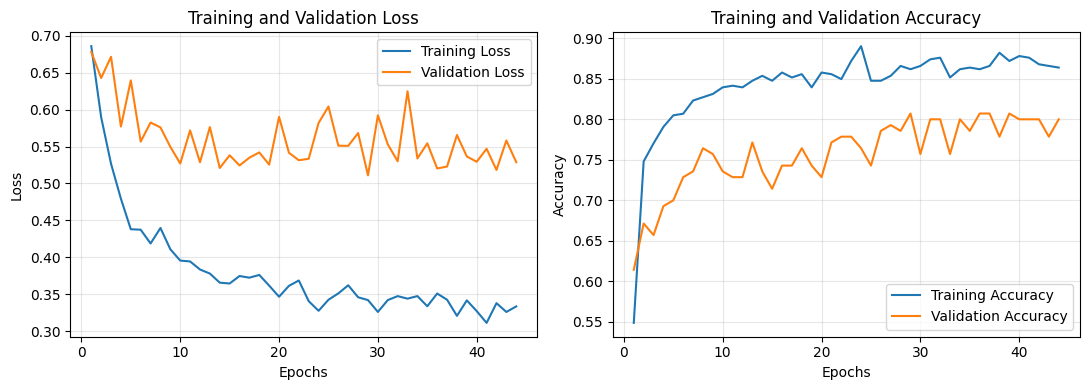

In [22]:
# ViT-B/16 (D1, Original, frozen backbone)
EPOCHS, PATIENCE, LR = 60, 15, 1e-3

train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_TRAIN, TF_IMAGENET_EVAL)

model = build_vit_b16(freeze_backbone=True)
optimizer, scheduler, warmup_epochs = make_vit_optimizer_and_scheduler(
    model, train_dl, epochs=EPOCHS, lr=LR)
loss_fn = nn.CrossEntropyLoss()

history = train_vit(model, train_dl, val_dl, optimizer, scheduler, loss_fn,
                    save_path=VIT_CHECKPOINTS['original_frozen'],
                    epochs=EPOCHS, patience=PATIENCE,
                    warmup_epochs=warmup_epochs, device=device)
plot_history(history)

### Original, frozen backbone - Test

--- ViT-B/16 (D1, Original, frozen backbone) - test ---
Test set: n = 72 | TB = 35 | Normal = 37
Acc. 0.7222  Prec. 0.9412  Sens. 0.4571  F1 0.6154  Spec. 0.9730  AUC 0.8162


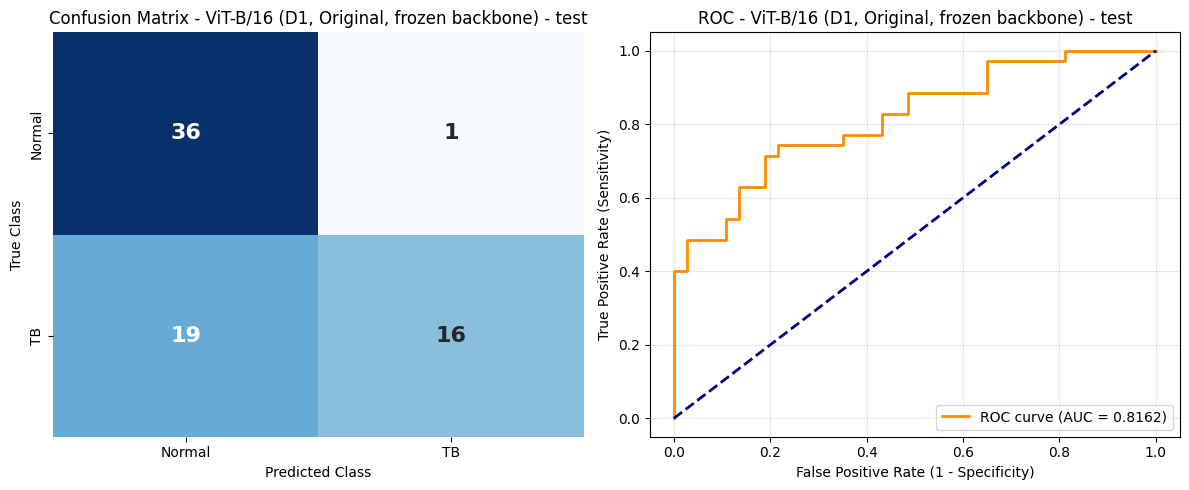

In [31]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_EVAL, TF_IMAGENET_EVAL)

model = load_checkpoint(VIT_CHECKPOINTS['original_frozen'], how='state_dict',
                        builder=lambda: build_vit_b16(freeze_backbone=True),
                        device=device)
metrics = evaluate_model(model, test_dl, device=device,
                         title='ViT-B/16 (D1, Original, frozen backbone) - test')
record_vit('original_frozen', metrics)

### Original, full fine-tuning - Training

LR 1e-4, an order of magnitude below the frozen run, because the pretrained
attention weights are now moving too.

40 epochs rather than D2's 20, again to partly offset the 16-batch epoch. This is
the run to watch for overfitting: 86M trainable parameters against 492 training
images. A training loss that reaches zero within a handful of epochs while
validation loss turns back upwards is the signature, and it is the reason the
frozen variant above is worth running at all on a dataset this small.

85,800,194 trainable params  |  lr 0.0001  wd 0.05  |  640 steps, 32 of them warmup (2 epoch(s))
Best model saved at epoch 1
Epoch [1/40]  lr 5.31e-05  train loss 0.6195  acc 0.6341  |  val loss 0.6037  acc 0.6429   [warmup - early stopping held off]
Epoch [2/40]  lr 1.00e-04  train loss 0.5400  acc 0.7419  |  val loss 0.7336  acc 0.5786   [warmup - early stopping held off]
Epoch [3/40]  lr 9.98e-05  train loss 0.3978  acc 0.8333  |  val loss 0.6986  acc 0.6643   [patience 1/10]
Epoch [4/40]  lr 9.93e-05  train loss 0.4428  acc 0.8049  |  val loss 0.6345  acc 0.6643   [patience 2/10]
Epoch [5/40]  lr 9.85e-05  train loss 0.3936  acc 0.8232  |  val loss 0.8478  acc 0.6500   [patience 3/10]
Epoch [6/40]  lr 9.73e-05  train loss 0.4290  acc 0.8191  |  val loss 0.6939  acc 0.6429   [patience 4/10]
Best model saved at epoch 7
Epoch [7/40]  lr 9.58e-05  train loss 0.3959  acc 0.8191  |  val loss 0.5626  acc 0.7286   [patience 0/10]
Epoch [8/40]  lr 9.40e-05  train loss 0.3085  acc 0.8801  | 

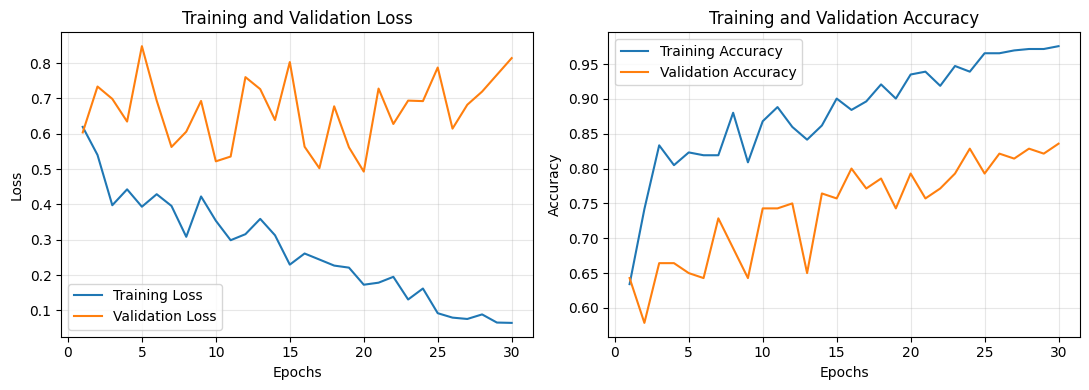

In [24]:
# ViT-B/16 (D1, Original, full fine-tuning)
EPOCHS, PATIENCE, LR = 40, 10, 1e-4

train_dl, val_dl, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_TRAIN, TF_IMAGENET_EVAL)

model = build_vit_b16(freeze_backbone=False)
optimizer, scheduler, warmup_epochs = make_vit_optimizer_and_scheduler(
    model, train_dl, epochs=EPOCHS, lr=LR)
loss_fn = nn.CrossEntropyLoss()

history = train_vit(model, train_dl, val_dl, optimizer, scheduler, loss_fn,
                    save_path=VIT_CHECKPOINTS['original_full_ft'],
                    epochs=EPOCHS, patience=PATIENCE,
                    warmup_epochs=warmup_epochs, device=device)
plot_history(history)

### Original, full fine-tuning - Test

--- ViT-B/16 (D1, Original, full fine-tuning) - test ---
Test set: n = 72 | TB = 35 | Normal = 37
Acc. 0.8472  Prec. 0.9286  Sens. 0.7429  F1 0.8254  Spec. 0.9459  AUC 0.9058


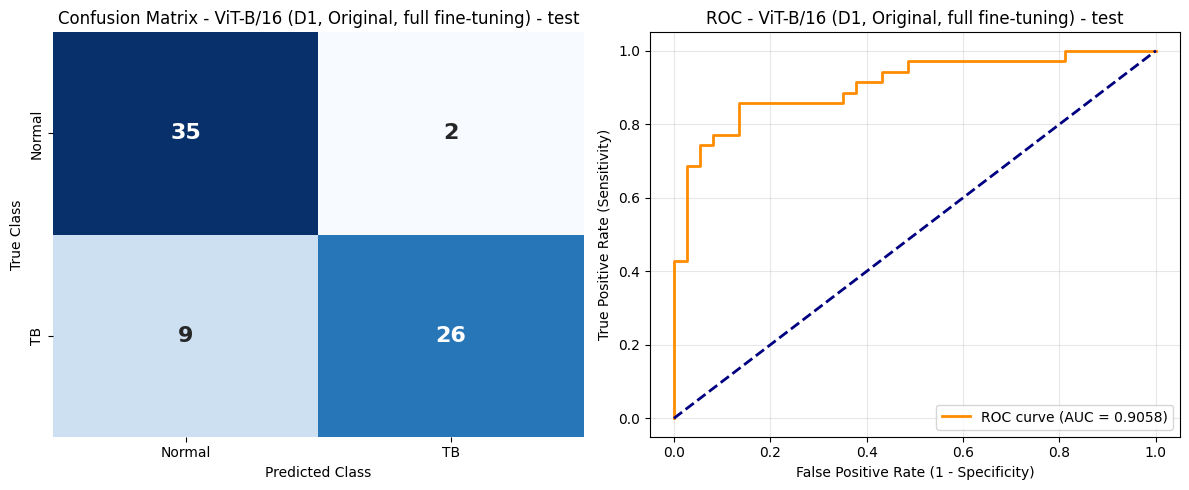

In [32]:
_, _, test_dl = make_loaders(DIR_ORIGINAL, TF_IMAGENET_EVAL, TF_IMAGENET_EVAL)

model = load_checkpoint(VIT_CHECKPOINTS['original_full_ft'], how='state_dict',
                        builder=lambda: build_vit_b16(freeze_backbone=False),
                        device=device)
metrics = evaluate_model(model, test_dl, device=device,
                         title='ViT-B/16 (D1, Original, full fine-tuning) - test')
record_vit('original_full_ft', metrics)

### Original - Grad-CAM and t-SNE

Set `CAM_RUN` and re-run for whichever of the two you want to look at. Worth doing
for both here: if the frozen and fully fine-tuned models attend to visibly
different regions while scoring the same on 72 test images, that is more
informative than the metric difference between them.

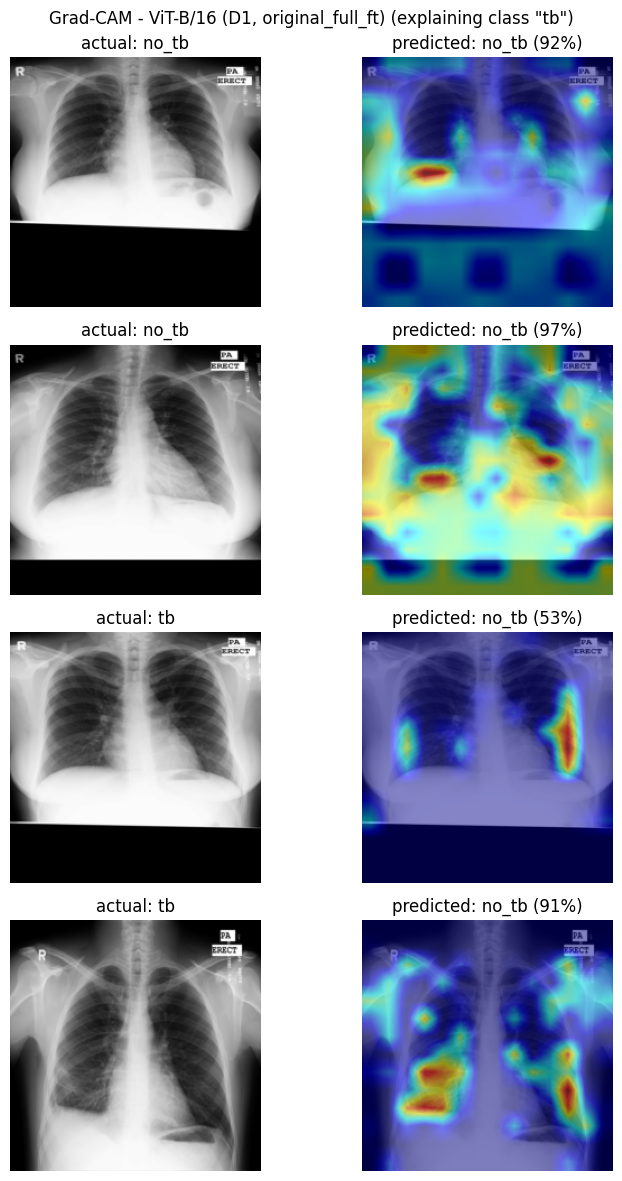

Collected 72 samples with 768 features each.


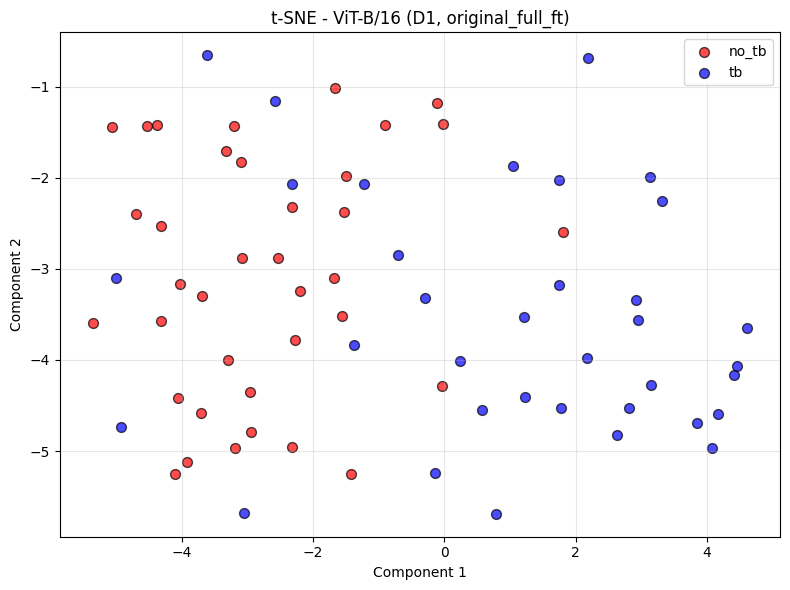

In [26]:
CAM_RUN = 'original_full_ft'      # or 'original_frozen'

test_dir = os.path.join(DIR_ORIGINAL, 'test')

model = load_checkpoint(VIT_CHECKPOINTS[CAM_RUN], how='state_dict',
                        builder=lambda: build_vit_b16(),
                        device=device)

plot_gradcam_vit(model, test_dir, TF_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
                 target_class=1, title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

_ = run_tsne_vit(model, test_dir, TF_IMAGENET_EVAL,
                 title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

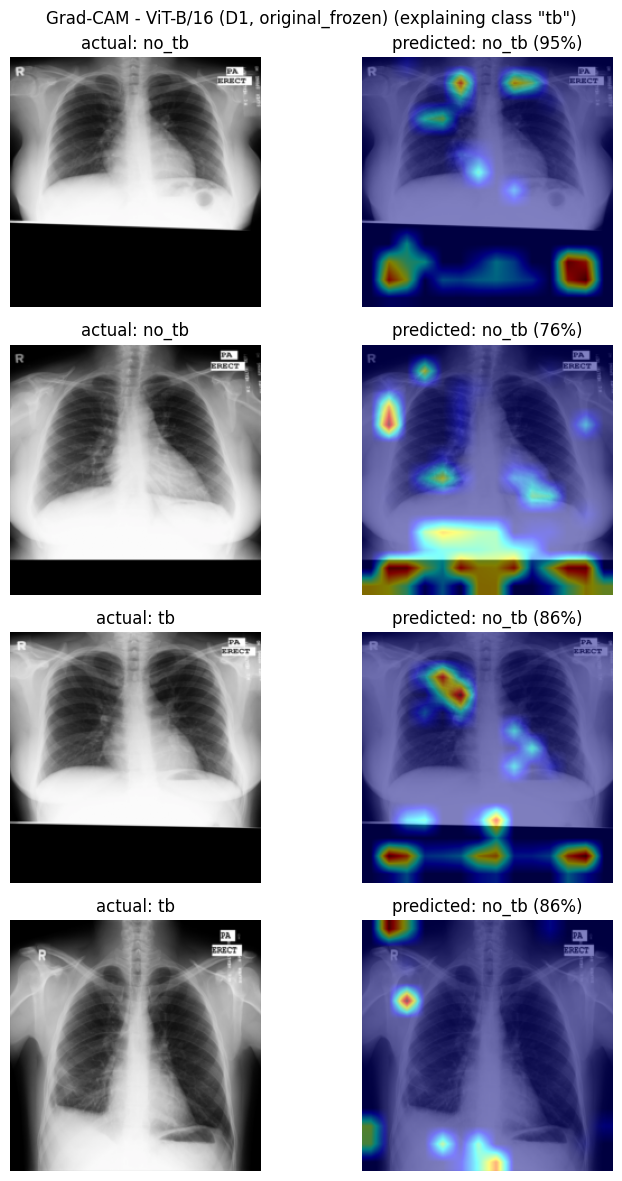

Collected 72 samples with 768 features each.


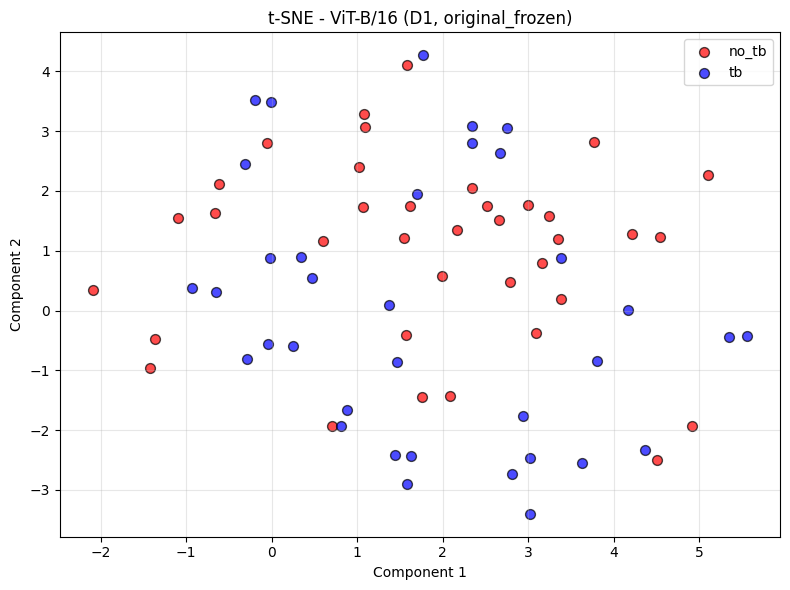

In [27]:
CAM_RUN = 'original_frozen'

test_dir = os.path.join(DIR_ORIGINAL, 'test')

model = load_checkpoint(VIT_CHECKPOINTS[CAM_RUN], how='state_dict',
                        builder=lambda: build_vit_b16(),
                        device=device)

plot_gradcam_vit(model, test_dir, TF_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
                 target_class=1, title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

_ = run_tsne_vit(model, test_dir, TF_IMAGENET_EVAL,
                 title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

### Segmented

The X-rays multiplied by their predicted lung masks, as hard attention.

**Prerequisite - section 5 must have been run in this session.** Nothing is
re-segmented here; this section only consumes `./data_704_seg`, which section 5
writes by running `seg_unet_2.pth` over all 704 images and then splitting the
masked results. A fresh Colab runtime starts with an empty local disk, so the check
below fails fast rather than part way into a training run.

Both D1 splits are 70/20/10, so the segmented test set is the same *size* as the
original one (72 images) - but section 5 orders the ROI images by `os.listdir()`
while section 4 orders them by `MetaData.csv`, so they are not the same 72 images.
The two schemes' numbers are comparable in the same loose sense they are for the
five CNNs, not image for image.

`TF_SEG_IMAGENET_TRAIN` carries no `Resize`: the ROI images are already 224x224.

In [15]:
# Fail fast if section 5's output is missing (a restarted runtime loses it).
if not os.path.isdir(os.path.join(DIR_SEGMENTED, 'train')):
    raise FileNotFoundError(
        f'{DIR_SEGMENTED} not found - run section 5 (Segmentation Pipeline) first.')

print(f'{DIR_SEGMENTED} (70/20/10 split of the masked images)')
for split in ['train', 'val', 'test']:
    n_tb = len(os.listdir(os.path.join(DIR_SEGMENTED, split, 'tb')))
    n_normal = len(os.listdir(os.path.join(DIR_SEGMENTED, split, 'no_tb')))
    print(f'  {split:5s}  TB {n_tb:4d}  Normal {n_normal:4d}  total {n_tb + n_normal:4d}')

./data_704_seg (70/20/10 split of the masked images)
  train  TB  241  Normal  251  total  492
  val    TB   69  Normal   71  total  140
  test   TB   35  Normal   37  total   72


### Segmented, frozen backbone - Training

Settings unchanged from the Original frozen run; only the data directory and the
transforms differ.

1,538 trainable params  |  lr 0.001  wd 0.05  |  960 steps, 48 of them warmup (3 epoch(s))
Best model saved at epoch 1
Epoch [1/60]  lr 3.54e-04  train loss 0.7178  acc 0.4472  |  val loss 0.6718  acc 0.6643   [warmup - early stopping held off]
Best model saved at epoch 2
Epoch [2/60]  lr 6.87e-04  train loss 0.6206  acc 0.6951  |  val loss 0.5815  acc 0.7286   [warmup - early stopping held off]
Best model saved at epoch 3
Epoch [3/60]  lr 1.00e-03  train loss 0.5395  acc 0.7480  |  val loss 0.5400  acc 0.7214   [warmup - early stopping held off]
Epoch [4/60]  lr 9.99e-04  train loss 0.4858  acc 0.7785  |  val loss 0.5432  acc 0.7143   [patience 1/15]
Best model saved at epoch 5
Epoch [5/60]  lr 9.97e-04  train loss 0.4968  acc 0.7825  |  val loss 0.5322  acc 0.7643   [patience 0/15]
Best model saved at epoch 6
Epoch [6/60]  lr 9.93e-04  train loss 0.4450  acc 0.8069  |  val loss 0.5104  acc 0.7929   [patience 0/15]
Epoch [7/60]  lr 9.88e-04  train loss 0.4223  acc 0.8252  |  val loss 

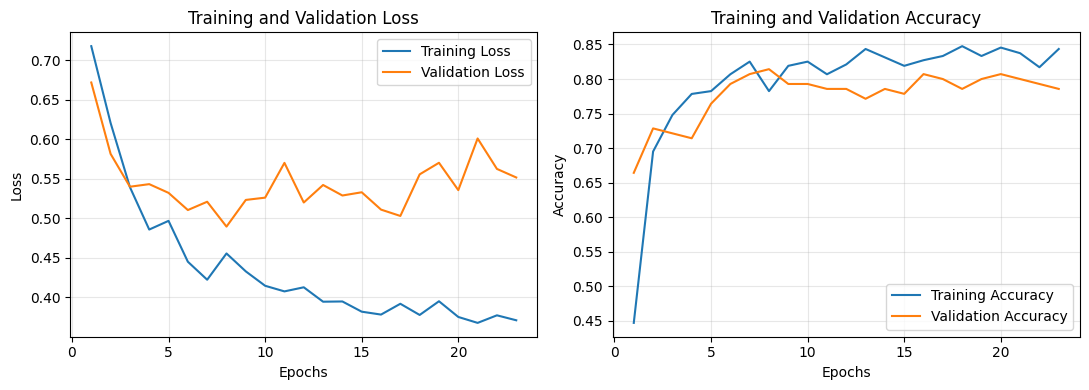

In [24]:
# ViT-B/16 (D1, Segmented, frozen backbone)
EPOCHS, PATIENCE, LR = 60, 15, 1e-3

train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_TRAIN,
                                         TF_SEG_IMAGENET_EVAL)

model = build_vit_b16(freeze_backbone=True)
optimizer, scheduler, warmup_epochs = make_vit_optimizer_and_scheduler(
    model, train_dl, epochs=EPOCHS, lr=LR)
loss_fn = nn.CrossEntropyLoss()

history = train_vit(model, train_dl, val_dl, optimizer, scheduler, loss_fn,
                    save_path=VIT_CHECKPOINTS['segmented_frozen'],
                    epochs=EPOCHS, patience=PATIENCE,
                    warmup_epochs=warmup_epochs, device=device)
plot_history(history)

### Segmented, frozen backbone - Test

--- ViT-B/16 (D1, Segmented, frozen backbone) - test ---
Test set: n = 72 | TB = 35 | Normal = 37
Acc. 0.7778  Prec. 0.7568  Sens. 0.8000  F1 0.7778  Spec. 0.7568  AUC 0.8610


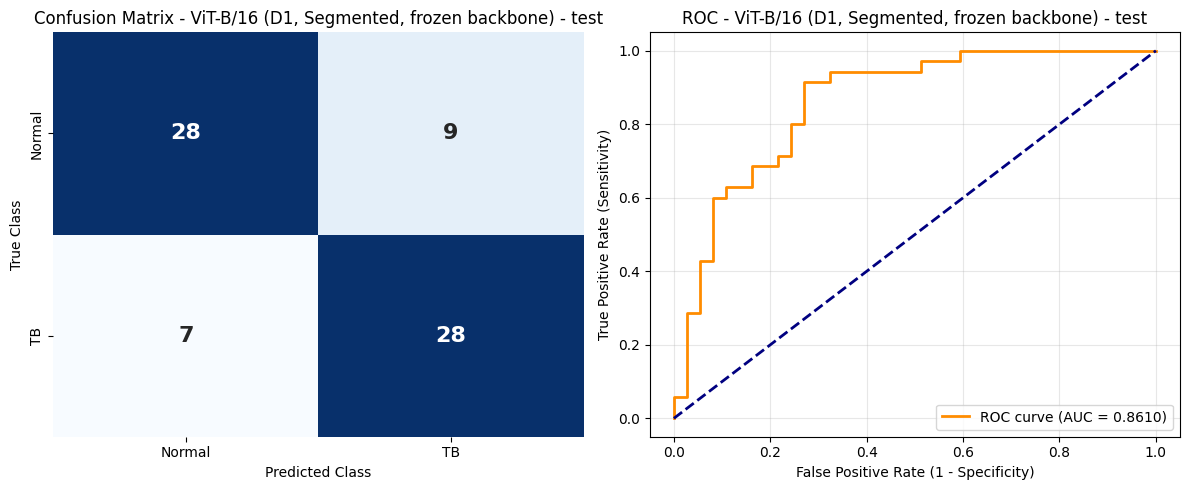

In [25]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_EVAL, TF_SEG_IMAGENET_EVAL)

model = load_checkpoint(VIT_CHECKPOINTS['segmented_frozen'], how='state_dict',
                        builder=lambda: build_vit_b16(freeze_backbone=True),
                        device=device)
metrics = evaluate_model(model, test_dl, device=device,
                         title='ViT-B/16 (D1, Segmented, frozen backbone) - test')
record_vit('segmented_frozen', metrics)

### Segmented, full fine-tuning - Training

Settings unchanged from the Original full fine-tune; only the data directory and
the transforms differ.

85,800,194 trainable params  |  lr 0.0001  wd 0.05  |  640 steps, 32 of them warmup (2 epoch(s))
Best model saved at epoch 1
Epoch [1/40]  lr 5.31e-05  train loss 0.6119  acc 0.6545  |  val loss 0.6935  acc 0.5071   [warmup - early stopping held off]
Best model saved at epoch 2
Epoch [2/40]  lr 1.00e-04  train loss 0.5377  acc 0.7276  |  val loss 0.6883  acc 0.7143   [warmup - early stopping held off]
Best model saved at epoch 3
Epoch [3/40]  lr 9.98e-05  train loss 0.6284  acc 0.6687  |  val loss 0.6652  acc 0.7143   [patience 0/10]
Best model saved at epoch 4
Epoch [4/40]  lr 9.93e-05  train loss 0.5506  acc 0.6748  |  val loss 0.5983  acc 0.7571   [patience 0/10]
Best model saved at epoch 5
Epoch [5/40]  lr 9.85e-05  train loss 0.4593  acc 0.8130  |  val loss 0.4974  acc 0.8071   [patience 0/10]
Epoch [6/40]  lr 9.73e-05  train loss 0.3960  acc 0.8252  |  val loss 0.5325  acc 0.7929   [patience 1/10]
Epoch [7/40]  lr 9.58e-05  train loss 0.3936  acc 0.8354  |  val loss 0.5599  acc 0

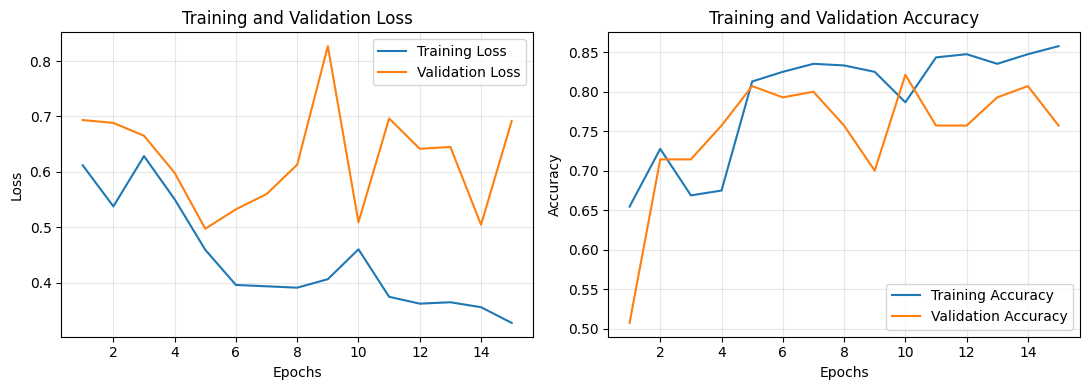

In [26]:
# ViT-B/16 (D1, Segmented, full fine-tuning)
EPOCHS, PATIENCE, LR = 40, 10, 1e-4

train_dl, val_dl, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_TRAIN,
                                         TF_SEG_IMAGENET_EVAL)

model = build_vit_b16(freeze_backbone=False)
optimizer, scheduler, warmup_epochs = make_vit_optimizer_and_scheduler(
    model, train_dl, epochs=EPOCHS, lr=LR)
loss_fn = nn.CrossEntropyLoss()

history = train_vit(model, train_dl, val_dl, optimizer, scheduler, loss_fn,
                    save_path=VIT_CHECKPOINTS['segmented_full_ft'],
                    epochs=EPOCHS, patience=PATIENCE,
                    warmup_epochs=warmup_epochs, device=device)
plot_history(history)

### Segmented, full fine-tuning - Test

--- ViT-B/16 (D1, Segmented, full fine-tuning) - test ---
Test set: n = 72 | TB = 35 | Normal = 37
Acc. 0.8194  Prec. 0.8438  Sens. 0.7714  F1 0.8060  Spec. 0.8649  AUC 0.9050


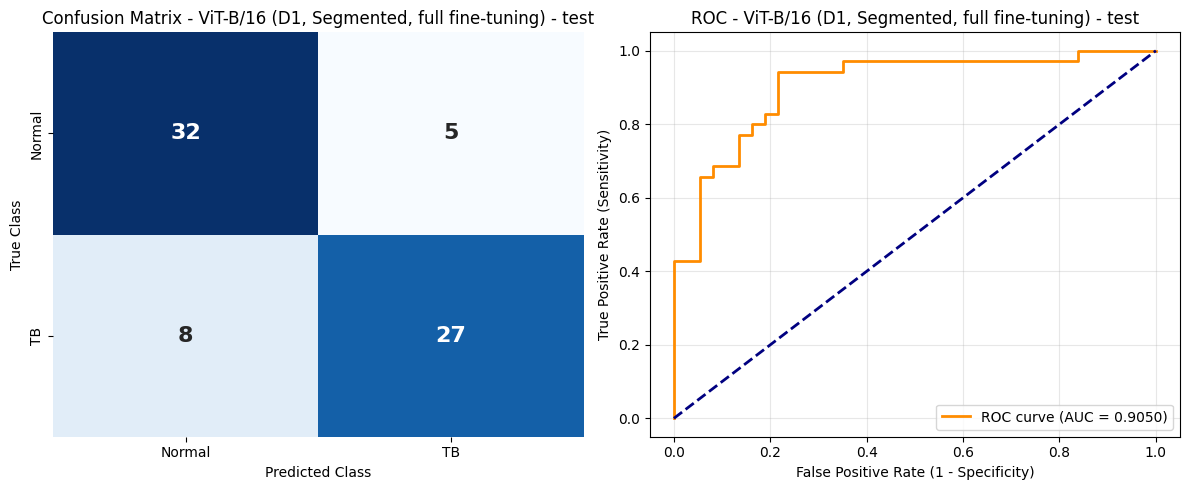

In [27]:
_, _, test_dl = make_loaders(DIR_SEGMENTED, TF_SEG_IMAGENET_EVAL, TF_SEG_IMAGENET_EVAL)

model = load_checkpoint(VIT_CHECKPOINTS['segmented_full_ft'], how='state_dict',
                        builder=lambda: build_vit_b16(freeze_backbone=False),
                        device=device)
metrics = evaluate_model(model, test_dl, device=device,
                         title='ViT-B/16 (D1, Segmented, full fine-tuning) - test')
record_vit('segmented_full_ft', metrics)

### Segmented - Grad-CAM and t-SNE

Everything outside the predicted lung mask is zero here, so if the attention maps
still key on the black surround, the model is reading a mask-border artefact rather
than the lungs. That is the main thing these figures are for.

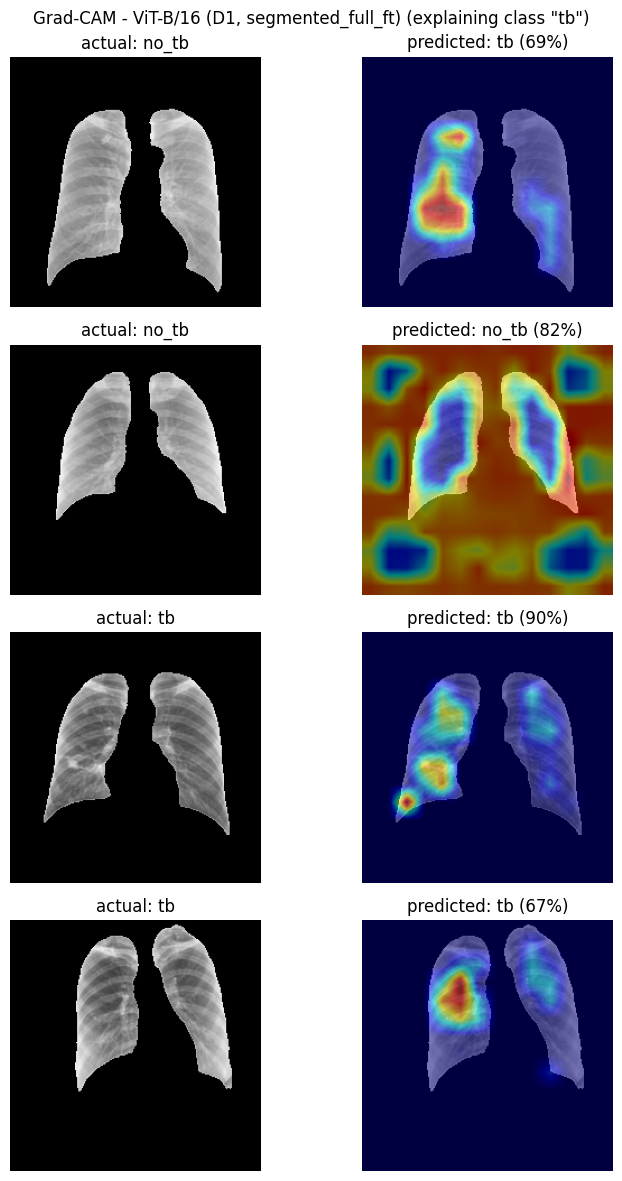

Collected 72 samples with 768 features each.


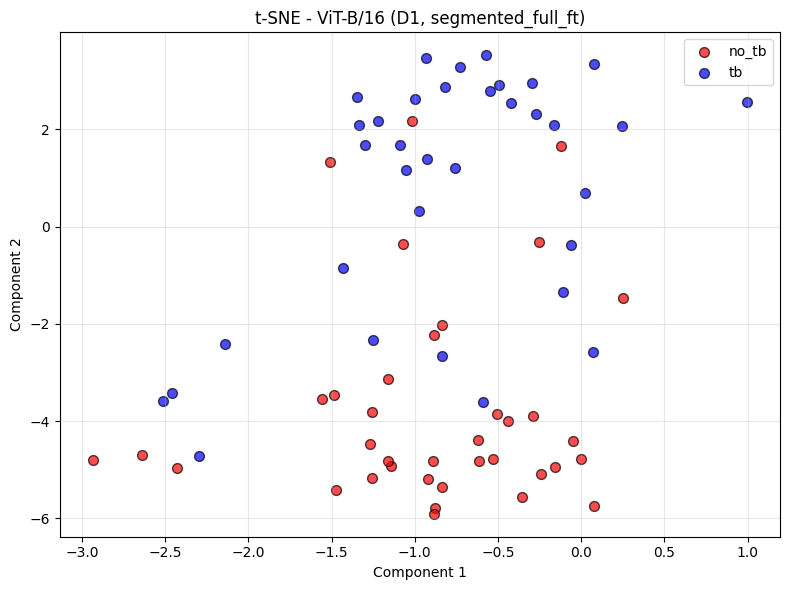

In [28]:
CAM_RUN = 'segmented_full_ft'      # or 'segmented_frozen'

test_dir = os.path.join(DIR_SEGMENTED, 'test')

model = load_checkpoint(VIT_CHECKPOINTS[CAM_RUN], how='state_dict',
                        builder=lambda: build_vit_b16(),
                        device=device)

plot_gradcam_vit(model, test_dir, TF_SEG_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
                 target_class=1, title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

_ = run_tsne_vit(model, test_dir, TF_SEG_IMAGENET_EVAL,
                 title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

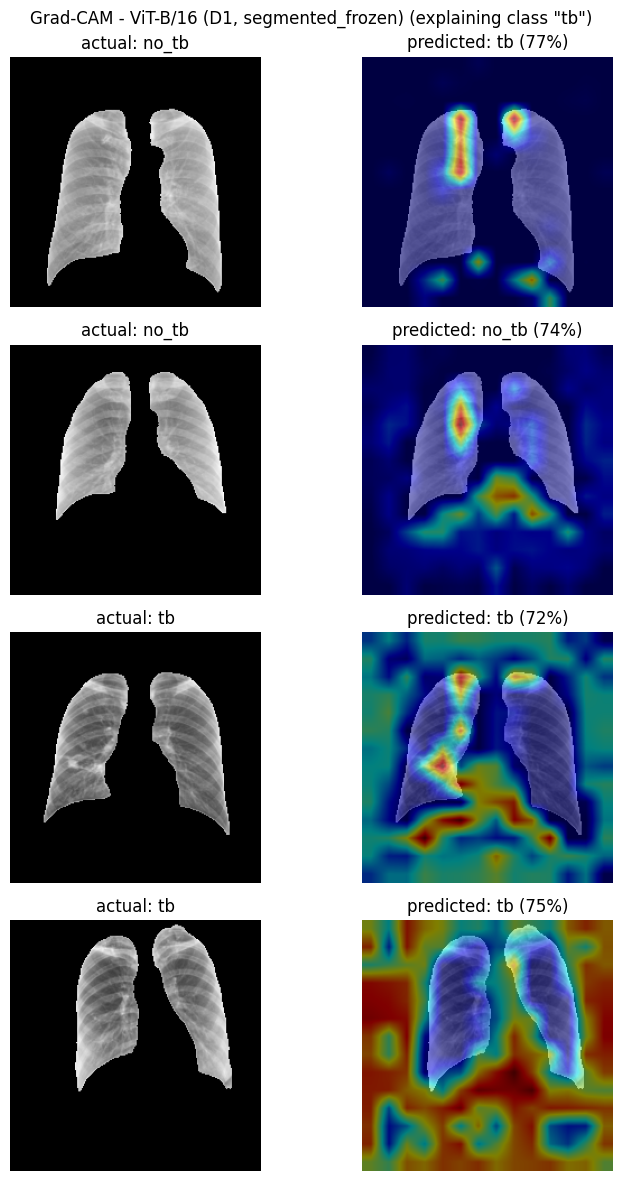

Collected 72 samples with 768 features each.


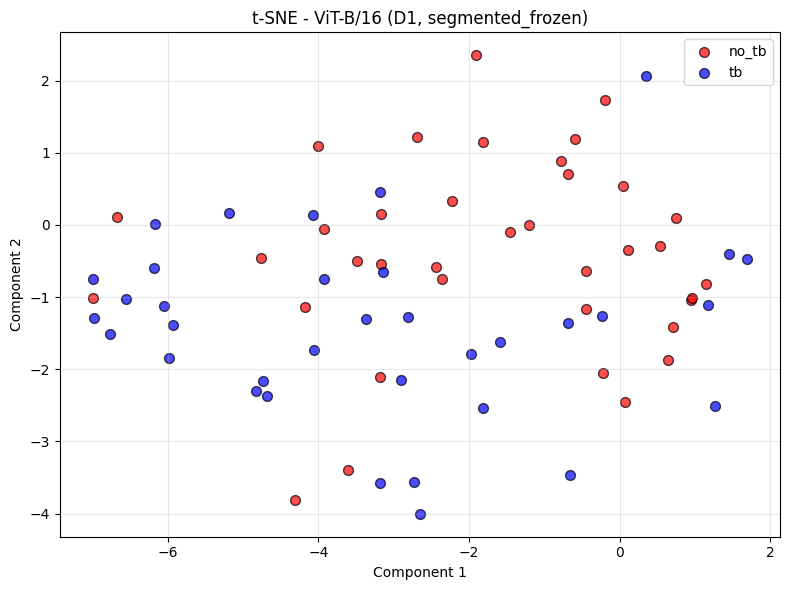

In [29]:
CAM_RUN = 'segmented_frozen'      # or 'segmented_frozen'

test_dir = os.path.join(DIR_SEGMENTED, 'test')

model = load_checkpoint(VIT_CHECKPOINTS[CAM_RUN], how='state_dict',
                        builder=lambda: build_vit_b16(),
                        device=device)

plot_gradcam_vit(model, test_dir, TF_SEG_IMAGENET_EVAL, *(IMAGENET_MEAN, IMAGENET_STD),
                 target_class=1, title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

_ = run_tsne_vit(model, test_dir, TF_SEG_IMAGENET_EVAL,
                 title=f'ViT-B/16 (D1, {CAM_RUN})', device=device)

### ViT Metrics Table

All four runs, by row.

Read it with the 72-image test split in mind: the whole table spans at most a
handful of individual images, so treat a one- or two-point gap as a tie rather than
a result.

In [33]:
vit_summary = pd.DataFrame(vit_results).T
vit_summary = vit_summary.reindex([k for k in VIT_RUN_ORDER if k in vit_summary.index])

print('ViT-B/16 (D1) - test metrics per run')
display(vit_summary.round(4))

ViT-B/16 (D1) - test metrics per run


,Acc.,Prec.,Sens.,F1,Spec.,AUC
original_frozen,0.7222,0.9412,0.4571,0.6154,0.9730,0.8162
original_full_ft,0.8472,0.9286,0.7429,0.8254,0.9459,0.9058
segmented_frozen,0.7778,0.7568,0.8000,0.7778,0.7568,0.8610
segmented_full_ft,0.8194,0.8438,0.7714,0.8060,0.8649,0.9050


# 7. Summary Table

In [ ]:
summary = pd.DataFrame([
    {'Model': model_name, 'Scheme': scheme, **metrics}
    for (model_name, scheme), metrics in results.items()
]).set_index(['Model', 'Scheme'])

# configuration order rather than execution order
order = [(m, s) for m in CHECKPOINTS for s in ['original', 'segmented']]
summary = summary.reindex([k for k in order if k in summary.index])

print('D1 (704) results on the D1 test split')
display(summary.round(4))